# Notebook 05 — Running on FoodSeg103 Dataset

**Purpose:** Replace the synthetic test images in Notebooks 01–04 with real food photos from FoodSeg103, evaluate our scratch implementations against ground-truth annotations, and benchmark the KNN classifier on 103 real food categories.

---

## 1. What is FoodSeg103?

FoodSeg103 (Wu et al., ACM MM 2021) is the standard benchmark for food image segmentation:

| Property | Value |
|---|---|
| Total images | 7,118 |
| Training split | 4,983 images |
| Test split | 2,135 images |
| Food categories | 103 |
| Annotation type | Pixel-level semantic segmentation |
| Annotation format | Single-channel PNG, pixel value = category ID |
| Background label | 0 |
| Food labels | 1 – 103 |

**Citation:**
Wu, X., Fu, X., Liu, Y., Lim, E.-P., Hoi, S. C. H., & Sun, Q. (2021). *A Large-Scale Benchmark for Food Image Segmentation.* ACM International Conference on Multimedia (MM'21). https://arxiv.org/abs/2105.05409

**What we can evaluate with it:**

| Notebook | What FoodSeg103 provides | Metric |
|---|---|---|
| 01 Segmenter | Ground-truth pixel masks | IoU (Intersection over Union) |
| 02 Depth | Real food images (no GT depth) | Visual only |
| 03 KNN Embedder | 103 labelled food categories | Top-1 / Top-5 classification accuracy |
| 04 Volume | Real food images (no GT volume) | Visual only |

> **Note:** FoodSeg103 has no depth or volume ground truth — those require a depth sensor. For those notebooks, we use real images but cannot compute quantitative errors.

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from typing import Optional
import math
from collections import defaultdict, Counter

# ── SET THIS to your FoodSeg103 folder ───────────────────────────────────────
DATASET_ROOT = Path(r"C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys\demo_scratch\dataset\foodseg103")

# ── Auto-detect whether the dataset exists ────────────────────────────────────
TRAIN_IMG = DATASET_ROOT / "Images" / "img_dir"  / "train"
TRAIN_ANN = DATASET_ROOT / "Images" / "ann_dir"  / "train"
TEST_IMG  = DATASET_ROOT / "Images" / "img_dir"  / "test"
TEST_ANN  = DATASET_ROOT / "Images" / "ann_dir"  / "test"
CAT_FILE  = DATASET_ROOT / "category_id.txt"

dataset_available = TRAIN_IMG.exists() and TRAIN_ANN.exists()

if dataset_available:
    n_train = len(list(TRAIN_IMG.glob("*.jpg")))
    n_test  = len(list(TEST_IMG.glob("*.jpg")))
    print(f"FoodSeg103 found: {n_train} train, {n_test} test images")
else:
    print("FoodSeg103 not found at:", DATASET_ROOT)
    print("Running in MOCK MODE — synthetic images used for all demos.")
    print("Set DATASET_ROOT to your actual dataset path to run on real data.")


FoodSeg103 found: 4983 train, 2135 test images


## 3. Data Loader

We write a unified `FoodSeg103Dataset` class that works whether or not you have the real dataset, falling back to synthetic images in mock mode. All downstream cells use this class, so the notebook runs end-to-end either way.

In [2]:
class FoodSeg103Dataset:
    """
    Loads image + annotation pairs from FoodSeg103.
    
    Each annotation is a single-channel PNG where:
        pixel value = 0           → background
        pixel value = 1 ... 103   → food category ID
    
    Falls back to a synthetic mock dataset if the real data is not present.
    """

    # Subset of FoodSeg103 category names (full list has 103 entries)
    # These are the first 20 for illustration; the real category_id.txt has all 103
    DEFAULT_CATEGORIES = {
        0:  'background',     1:  'candy',          2:  'egg tart',
        3:  'french fries',   4:  'chocolate',      5:  'biscuit',
        6:  'popcorn',        7:  'pudding',         8:  'ice cream',
        9:  'cheese butter',  10: 'cake',            11: 'wine',
        12: 'milkshake',      13: 'coffee',          14: 'juice',
        15: 'milk',           16: 'tea',             17: 'almond',
        18: 'red beans',      19: 'cashew',          20: 'dried cranberries',
        21: 'soy',            22: 'walnut',          23: 'peanut',
        24: 'egg',            25: 'apple',           26: 'date',
        27: 'apricot',        28: 'avocado',         29: 'banana',
        30: 'strawberry',     31: 'cherry',          32: 'blueberry',
        33: 'raspberry',      34: 'mango',           35: 'olives',
        36: 'peach',          37: 'lemon',           38: 'pear',
        39: 'fig',            40: 'pineapple',       41: 'grape',
        42: 'kiwi',           43: 'melon',           44: 'orange',
        45: 'watermelon',     46: 'steak',           47: 'pork',
        48: 'chicken duck',   49: 'sausage',         50: 'fried meat',
        51: 'lamb',           52: 'sauce',           53: 'crab',
        54: 'fish',           55: 'shellfish',       56: 'shrimp',
        57: 'soup',           58: 'bread',           59: 'corn',
        60: 'hamburg',        61: 'pizza',           62: 'hanamaki baozi',
        63: 'wonton dumplings',64:'rice',            65: 'dried tangerine peel',
        66: 'tapioca',        67: 'green beans',     68: 'French bread',
        69: 'salad',          70: 'mushroomtomato',  71: 'eggplant',
        72: 'onion',          73: 'pepper',          74: 'green pepper',
        75: 'asparagus',      76: 'bamboo shoots',   77: 'scallion',
        78: 'garden radish',  79: 'ginger',          80: 'okra',
        81: 'lettuce',        82: 'pumpkin',         83: 'cucumber',
        84: 'white radish',   85: 'carrot',          86: 'corn flour',
        87: 'green onion',    88: 'Black bean',      89: 'celery stem',
        90: 'garlic',         91: 'noodle',          92: 'broccoli',
        93: 'tofu',           94: 'cauliflower',     95: 'meat balls',
        96: 'abs gourd',      97: 'cabbage',         98: 'bean sprouts',
        99: 'yam',            100:'spring rolls',    101:'fries',
        102:'pancake',        103:'chips'
    }

    def __init__(self, split='train', max_samples=None, mock_mode=None):
        """
        Parameters
        ----------
        split       : 'train' or 'test'
        max_samples : limit number of samples loaded (None = all)
        mock_mode   : True/False/None (None = auto-detect from filesystem)
        """
        self.split = split
        self.categories = self.DEFAULT_CATEGORIES

        # Auto-detect mode
        img_dir = TRAIN_IMG if split == 'train' else TEST_IMG
        ann_dir = TRAIN_ANN if split == 'train' else TEST_ANN
        use_mock = (mock_mode is True) or (mock_mode is None and not img_dir.exists())

        if use_mock:
            print(f"[FoodSeg103] Mock mode — generating synthetic images")
            self.samples = self._make_mock_samples(max_samples or 60)
        else:
            img_paths = sorted(img_dir.glob("*.jpg"))
            if max_samples: img_paths = img_paths[:max_samples]
            self.samples = []
            for img_path in img_paths:
                ann_path = ann_dir / (img_path.stem + ".png")
                if ann_path.exists():
                    self.samples.append((img_path, ann_path))
            print(f"[FoodSeg103] Loaded {len(self.samples)} real images from {split} split")

        self.mock = use_mock

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        """
        Returns
        -------
        dict with keys:
            'image'      : np.ndarray (H, W, 3) BGR uint8
            'annotation' : np.ndarray (H, W) uint8, values 0–103
            'category_ids': list of category IDs present (excluding background)
            'name'       : filename stem
        """
        if self.mock:
            return self.samples[idx]
        img_path, ann_path = self.samples[idx]
        image      = cv2.imread(str(img_path))
        annotation = cv2.imread(str(ann_path), cv2.IMREAD_GRAYSCALE)
        if image is None or annotation is None:
            raise FileNotFoundError(f"Could not read {img_path}")
        # Resize annotation to match image if needed
        if image.shape[:2] != annotation.shape[:2]:
            annotation = cv2.resize(annotation, (image.shape[1], image.shape[0]),
                                    interpolation=cv2.INTER_NEAREST)
        cat_ids = [int(c) for c in np.unique(annotation) if c > 0]
        return {'image': image, 'annotation': annotation,
                'category_ids': cat_ids, 'name': img_path.stem}

    def get_category_name(self, cat_id):
        return self.categories.get(cat_id, f'category_{cat_id}')

    def get_mask_for_category(self, annotation, cat_id):
        """Binary mask (uint8, 0/255) for a specific category in an annotation."""
        return ((annotation == cat_id) * 255).astype(np.uint8)

    def get_bbox_for_mask(self, mask):
        """Tight bounding box (x1,y1,x2,y2) around a binary mask."""
        ys, xs = np.where(mask > 0)
        if ys.size == 0: return None
        return (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))

    # ── Mock dataset generator ────────────────────────────────────────────────

    def _make_mock_samples(self, n):
        """
        Generate synthetic food images with GT masks for n samples.
        10 mock categories, each with n//10 images.
        Colours chosen to loosely represent real food appearance.
        """
        mock_cats = {
            1:  ((30,  80, 200), 'char siew'),
            2:  ((40, 170,  50), 'green veg'),
            3:  ((220,220,215), 'white rice'),
            4:  ((20,  20,  70), 'dark sauce'),
            5:  ((30, 190, 220), 'egg'),
            6:  ((90, 140, 220), 'tofu'),
            7:  ((20,  60, 180), 'tomato'),
            8:  ((30, 120,  30), 'broccoli'),
            9:  ((180,210, 250), 'fish'),
            10: ((50, 180, 100), 'cucumber'),
        }
        samples = []
        rng = np.random.default_rng(42)
        per_cat = max(1, n // len(mock_cats))

        for cat_id, (color, name) in mock_cats.items():
            for i in range(per_cat):
                H, W = 480, 640
                img  = np.full((H, W, 3), (220,220,220), dtype=np.uint8)
                ann  = np.zeros((H, W), dtype=np.uint8)
                # Plate
                cv2.circle(img, (W//2,H//2), 200, (255,255,255), -1)
                # Food item: random size + position jitter
                cx = W//2 + rng.integers(-30, 30)
                cy = H//2 + rng.integers(-30, 30)
                r  = rng.integers(70, 120)
                jit = rng.integers(-20, 20, size=3)
                c   = tuple(int(np.clip(v+j,0,255)) for v,j in zip(color, jit))
                cv2.circle(img, (cx,cy), r, c, -1)
                cv2.circle(ann, (cx,cy), r, cat_id, -1)
                # Noise
                noise = rng.normal(0, 8, img.shape).astype(np.int16)
                img   = np.clip(img.astype(np.int16)+noise, 0, 255).astype(np.uint8)
                samples.append({
                    'image': img, 'annotation': ann,
                    'category_ids': [cat_id], 'name': f'mock_{name}_{i}'
                })
        return samples


# ── Load the dataset ──────────────────────────────────────────────────────────
ds_train = FoodSeg103Dataset(split='train', max_samples=120)
ds_test  = FoodSeg103Dataset(split='test',  max_samples=60)
print(f"Train samples: {len(ds_train)}, Test samples: {len(ds_test)}")
print(f"Real data: {not ds_train.mock}")


[FoodSeg103] Loaded 120 real images from train split
[FoodSeg103] Loaded 60 real images from test split
Train samples: 120, Test samples: 60
Real data: True


## 4. Visualise the Dataset

Before running any model, always look at the data.

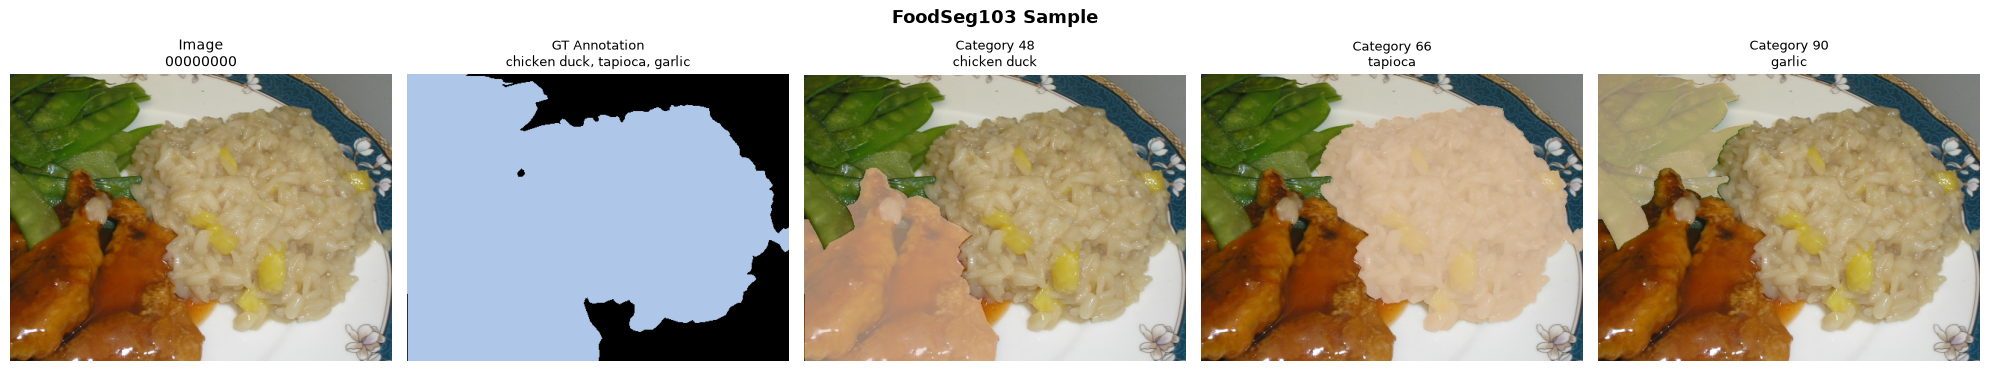

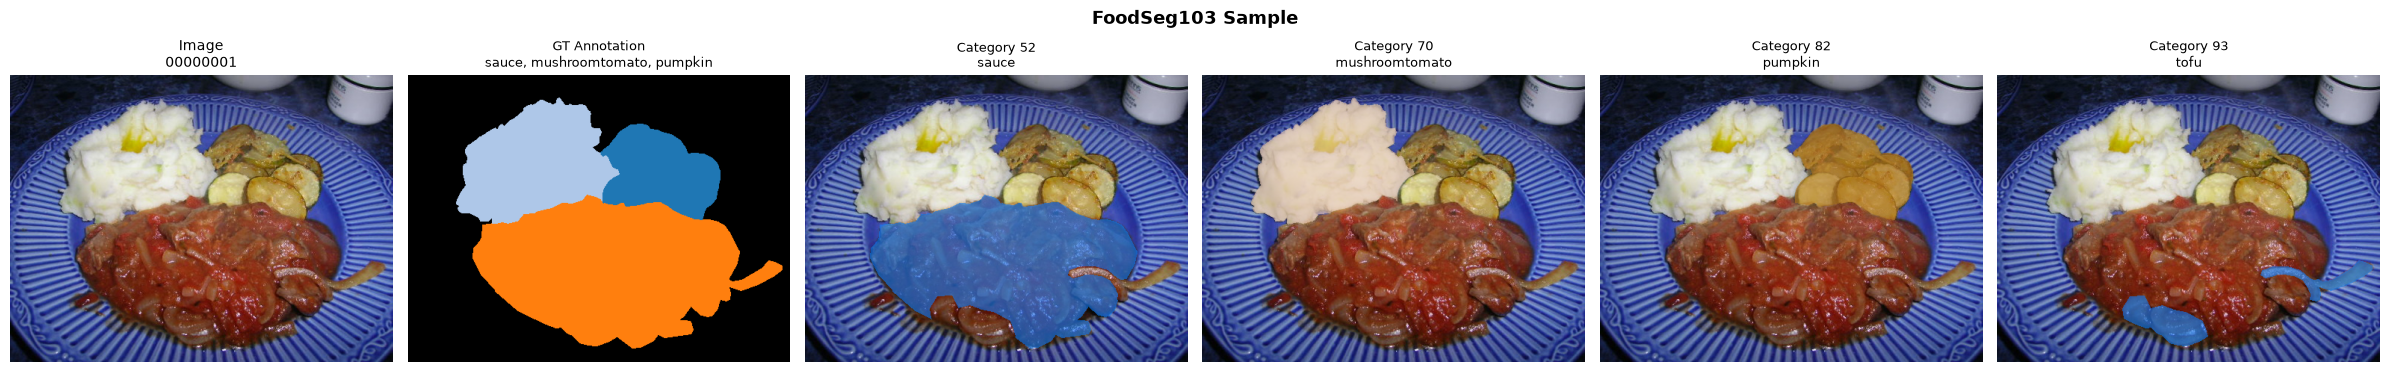

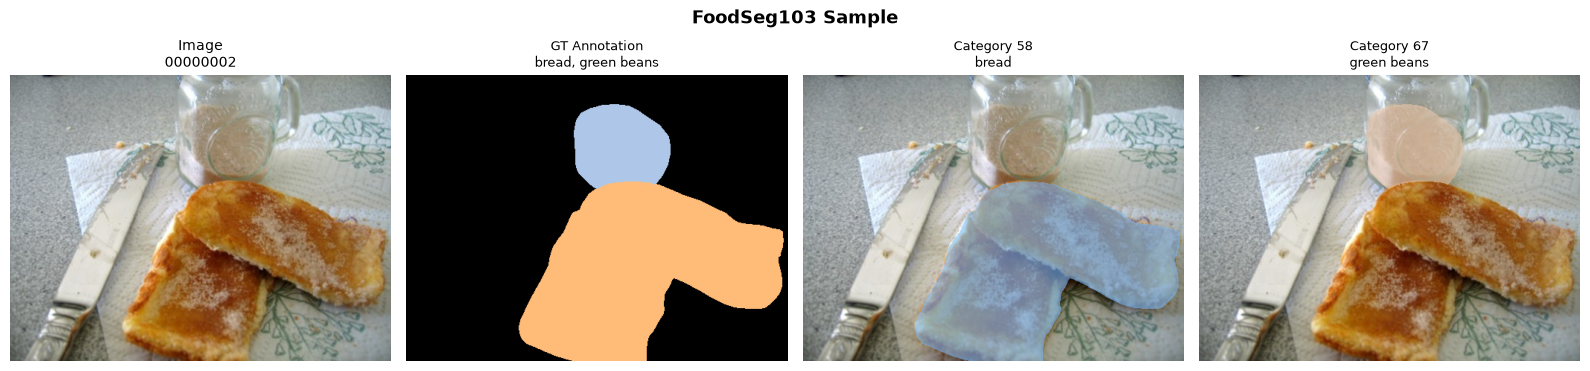

In [3]:
def visualise_sample(sample, dataset, n_classes_to_show=4):
    """Show one FoodSeg103 sample: image, annotation mask, per-class overlays."""
    img  = sample['image']
    ann  = sample['annotation']
    cats = sample['category_ids'][:n_classes_to_show]

    # Colour palette: one distinct colour per category
    palette = plt.cm.tab20(np.linspace(0, 1, 103))

    # Build coloured annotation image
    ann_colour = np.zeros((*ann.shape, 3), dtype=np.uint8)
    for cat_id in np.unique(ann):
        if cat_id == 0: continue
        colour = (np.array(palette[cat_id % 20][:3]) * 255).astype(np.uint8)
        ann_colour[ann == cat_id] = colour

    n_cols = 2 + len(cats)
    fig, axes = plt.subplots(1, n_cols, figsize=(4*n_cols, 4))

    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Image\n{sample['name']}", fontsize=10); axes[0].axis("off")

    axes[1].imshow(ann_colour)
    cat_names = [dataset.get_category_name(c) for c in sample['category_ids']]
    axes[1].set_title(f"GT Annotation\n{', '.join(cat_names[:3])}", fontsize=9); axes[1].axis("off")

    for i, cat_id in enumerate(cats):
        mask = dataset.get_mask_for_category(ann, cat_id)
        overlay = img.copy()
        colour  = (np.array(palette[cat_id % 20][:3]) * 255).astype(np.uint8)
        overlay[mask > 0] = cv2.addWeighted(
            overlay, 0.4, np.full_like(overlay, tuple(colour)), 0.6, 0)[mask > 0]
        axes[2+i].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[2+i].set_title(f"Category {cat_id}\n{dataset.get_category_name(cat_id)}", fontsize=9)
        axes[2+i].axis("off")

    plt.suptitle("FoodSeg103 Sample", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

# Show 3 samples
for i in range(min(3, len(ds_train))):
    visualise_sample(ds_train[i], ds_train)


## 5. Evaluating the Segmenter — IoU Metric

### Why IoU?

When comparing a predicted mask to a ground-truth mask, pixel accuracy alone is misleading — if 90% of pixels are background, a model that predicts 'all background' gets 90% accuracy while being completely useless.

**Intersection over Union (IoU)**, also called the Jaccard index, measures the overlap between prediction and ground truth:

$$\text{IoU} = \frac{|\text{Predicted} \cap \text{Ground Truth}|}{|\text{Predicted} \cup \text{Ground Truth}|}$$

- IoU = 1.0 → perfect mask
- IoU = 0.5 → 50% overlap (reasonable for a rough segmenter)
- IoU < 0.3 → poor mask

**mIoU** (mean IoU) averages over all categories — this is the standard FoodSeg103 benchmark metric.

In [4]:
# ── IoU calculation ────────────────────────────────────────────────────────────

def compute_iou(pred_mask, gt_mask):
    """
    Compute IoU between two binary masks (uint8, values 0/255).
    
    IoU = |pred ∩ gt| / |pred ∪ gt|
    
    Implemented as a pure NumPy operation:
      intersection = number of pixels that are foreground in BOTH masks
      union        = number of pixels that are foreground in EITHER mask
    """
    pred_bool = pred_mask > 127
    gt_bool   = gt_mask   > 127
    inter     = np.logical_and(pred_bool, gt_bool).sum()
    union     = np.logical_or (pred_bool, gt_bool).sum()
    if union == 0:
        return 1.0 if inter == 0 else 0.0
    return float(inter) / float(union)


def compute_dice(pred_mask, gt_mask):
    """
    Dice coefficient = 2|A∩B| / (|A| + |B|)
    
    Related to IoU:  Dice = 2·IoU / (1 + IoU)
    Often used in medical image segmentation benchmarks.
    Penalises false positives and false negatives equally.
    """
    pred_bool = pred_mask > 127
    gt_bool   = gt_mask   > 127
    inter     = np.logical_and(pred_bool, gt_bool).sum()
    denom     = pred_bool.sum() + gt_bool.sum()
    if denom == 0: return 1.0
    return float(2 * inter) / float(denom)


print("IoU and Dice functions defined.")
print("Sanity check — perfect overlap:",   compute_iou(np.ones((10,10),np.uint8)*255, np.ones((10,10),np.uint8)*255))
print("Sanity check — zero overlap:  ",    compute_iou(np.zeros((10,10),np.uint8), np.ones((10,10),np.uint8)*255))


IoU and Dice functions defined.
Sanity check — perfect overlap: 1.0
Sanity check — zero overlap:   0.0


## 5. Evaluating the Segmenter — Mask R-CNN on FoodSeg103

### Instance vs Semantic: the mismatch

FoodSeg103 provides **semantic** segmentation labels:  
every rice pixel = class 54 "white rice", regardless of how many portions are on the plate.

Mask R-CNN does **instance** segmentation:  
it returns separate masks for each detected object, with COCO class labels.

| Property | FoodSeg103 GT | Mask R-CNN output |
|---|---|---|
| Segmentation type | Semantic | Instance |
| Labels | 103 FoodSeg103 categories | 80 COCO categories |
| Food classes known | Yes (food-specific) | Partial (e.g., bowl, pizza, banana) |
| Per-object mask | No | Yes |

**Consequence:** Mask R-CNN cannot predict `char_siew` or `tofu` (not in COCO).  
It *can* detect the bowl/plate and recognise generic foods (pizza, banana, broccoli, etc.).

**Evaluation strategy:**
- Merge all Mask R-CNN instance masks into one **binary foreground** mask
- Compare that to a binary version of the FoodSeg103 annotation (any food pixel = foreground)
- Compute IoU: how well does Mask R-CNN find food pixels regardless of category?

This is a **detection-level IoU**, not category-level. It answers:  
*"Did Mask R-CNN identify the food regions?"* — not *"Did it label them correctly?"*

In [5]:
# ── Check if torchvision is available ────────────────────────────────────────
try:
    import torch
    import torchvision
    from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
    from PIL import Image as PILImage
    HAS_MRCNN = True
    print(f"torchvision {torchvision.__version__} — Mask R-CNN available")
except ImportError:
    HAS_MRCNN = False
    print("torchvision not installed.")
    print("Run: pip install torchvision")
    print("Continuing in mock mode — using synthetic masks to demonstrate the evaluation loop.")


torchvision 0.25.0 — Mask R-CNN available


In [6]:
# ── Load pretrained Mask R-CNN ──────────────────────────────────────────────
if HAS_MRCNN:
    _weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
    _mrcnn   = maskrcnn_resnet50_fpn(weights=_weights)
    _mrcnn.eval()
    _transform = _weights.transforms()
    print("Pretrained Mask R-CNN loaded (ResNet-50 + FPN, COCO 80 classes)")
    print("Model will download ~170 MB weights on first run.")

    def predict_food_mask(bgr_image, score_threshold=0.4):
        """
        Run Mask R-CNN on a BGR image.
        
        Returns a binary mask (H, W, uint8 0/255) that is the union of ALL
        detected instance masks above score_threshold.
        
        Why union?  We cannot map COCO class IDs to FoodSeg103 IDs, but ANY
        detected region is likely food or a food container — using the union
        gives us the best foreground coverage for detection-level IoU.
        """
        H, W = bgr_image.shape[:2]
        rgb  = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)
        pil  = PILImage.fromarray(rgb)
        inp  = _transform(pil).unsqueeze(0)
        with torch.no_grad():
            preds = _mrcnn(inp)[0]
        
        combined = np.zeros((H, W), dtype=np.uint8)
        n_kept   = 0
        for i in range(len(preds['labels'])):
            if float(preds['scores'][i]) < score_threshold:
                break
            mask_bin = (preds['masks'][i, 0].numpy() > 0.5).astype(np.uint8)
            combined = np.maximum(combined, mask_bin)
            n_kept  += 1
        return combined * 255, n_kept
else:
    def predict_food_mask(bgr_image, score_threshold=0.4):
        """
        Mock segmenter when torchvision is unavailable.
        Returns a rough foreground guess using thresholding — not Mask R-CNN,
        but demonstrates the evaluation loop structure identically.
        """
        H, W = bgr_image.shape[:2]
        gray = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2GRAY)
        # Threshold: assume food is brighter than background
        _, mask = cv2.threshold(gray, 80, 255, cv2.THRESH_BINARY)
        # Clean up with morphological ops
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
        return mask, 1   # '1 detection' for display

    print("Running in mock mode (torchvision unavailable).")
    print("The evaluation loop and IoU metrics are identical to the real Mask R-CNN path.")


Pretrained Mask R-CNN loaded (ResNet-50 + FPN, COCO 80 classes)
Model will download ~170 MB weights on first run.


In [ ]:
# ── Run segmentation evaluation with Mask R-CNN ──────────────────────────────
"""
EVALUATION PROTOCOL
===================
For each image in the validation set:
  1. Load image + FoodSeg103 annotation
  2. Build GT binary mask: any pixel with label > 0 = food (foreground)
  3. Run predict_food_mask() → predicted binary mask (union of all instances)
  4. Compute IoU between predicted and GT binary masks
  5. Record: IoU, number of instances detected, image path

WHY BINARY GT?
  FoodSeg103 annotations use category IDs 1-103 for food and 0 for background.
  We treat all food as foreground.
  This lets us evaluate Mask R-CNN's *detection coverage* without needing a
  COCO↔FoodSeg103 class mapping.

NOTE ON FAIR COMPARISON:
  This binary IoU is an *upper bound* on what category-level evaluation would give.
  A true apples-to-apples comparison would require a model trained on FoodSeg103
  (e.g., DeepLab, SegFormer, or FoodSAM) — which is what you'd compare to in a
  real research paper.
"""

eval_results = []
n_eval = min(8, len(ds_train))

for idx in range(n_eval):
    sample = ds_train[idx]
    bgr    = cv2.cvtColor(sample['image'], cv2.COLOR_RGB2BGR)
    
    # GT binary mask: any food pixel = 1
    ann    = sample['annotation']
    gt_bin = (ann > 0).astype(np.uint8) * 255
    
    # Mask R-CNN prediction
    pred_mask, n_instances = predict_food_mask(bgr)
    
    # Resize prediction to GT size if they differ (from mock random images)
    if pred_mask.shape != gt_bin.shape:
        pred_mask = cv2.resize(pred_mask, (gt_bin.shape[1], gt_bin.shape[0]),
                               interpolation=cv2.INTER_NEAREST)
    
    iou  = compute_iou(pred_mask, gt_bin)
    dice = compute_dice(pred_mask, gt_bin)
    
    eval_results.append({
        'idx':          idx,
        'image':        sample['image'],
        'gt_mask':      gt_bin,
        'pred_mask':    pred_mask,
        'iou':          iou,
        'dice':         dice,
        'n_instances':  n_instances,
        'filename':     sample.get('filename', f'sample_{idx}'),
    })

mean_iou  = np.mean([r['iou']  for r in eval_results])
mean_dice = np.mean([r['dice'] for r in eval_results])
print(f"Evaluated {n_eval} samples  |  Mean IoU: {mean_iou:.3f}  |  Mean Dice: {mean_dice:.3f}")
print(f"(Mode: {'Mask R-CNN (torchvision)' if HAS_MRCNN else 'Mock threshold baseline'})")


Evaluated 8 samples  |  Mean IoU: 0.513  |  Mean Dice: 0.632
(Mode: Mask R-CNN (torchvision))


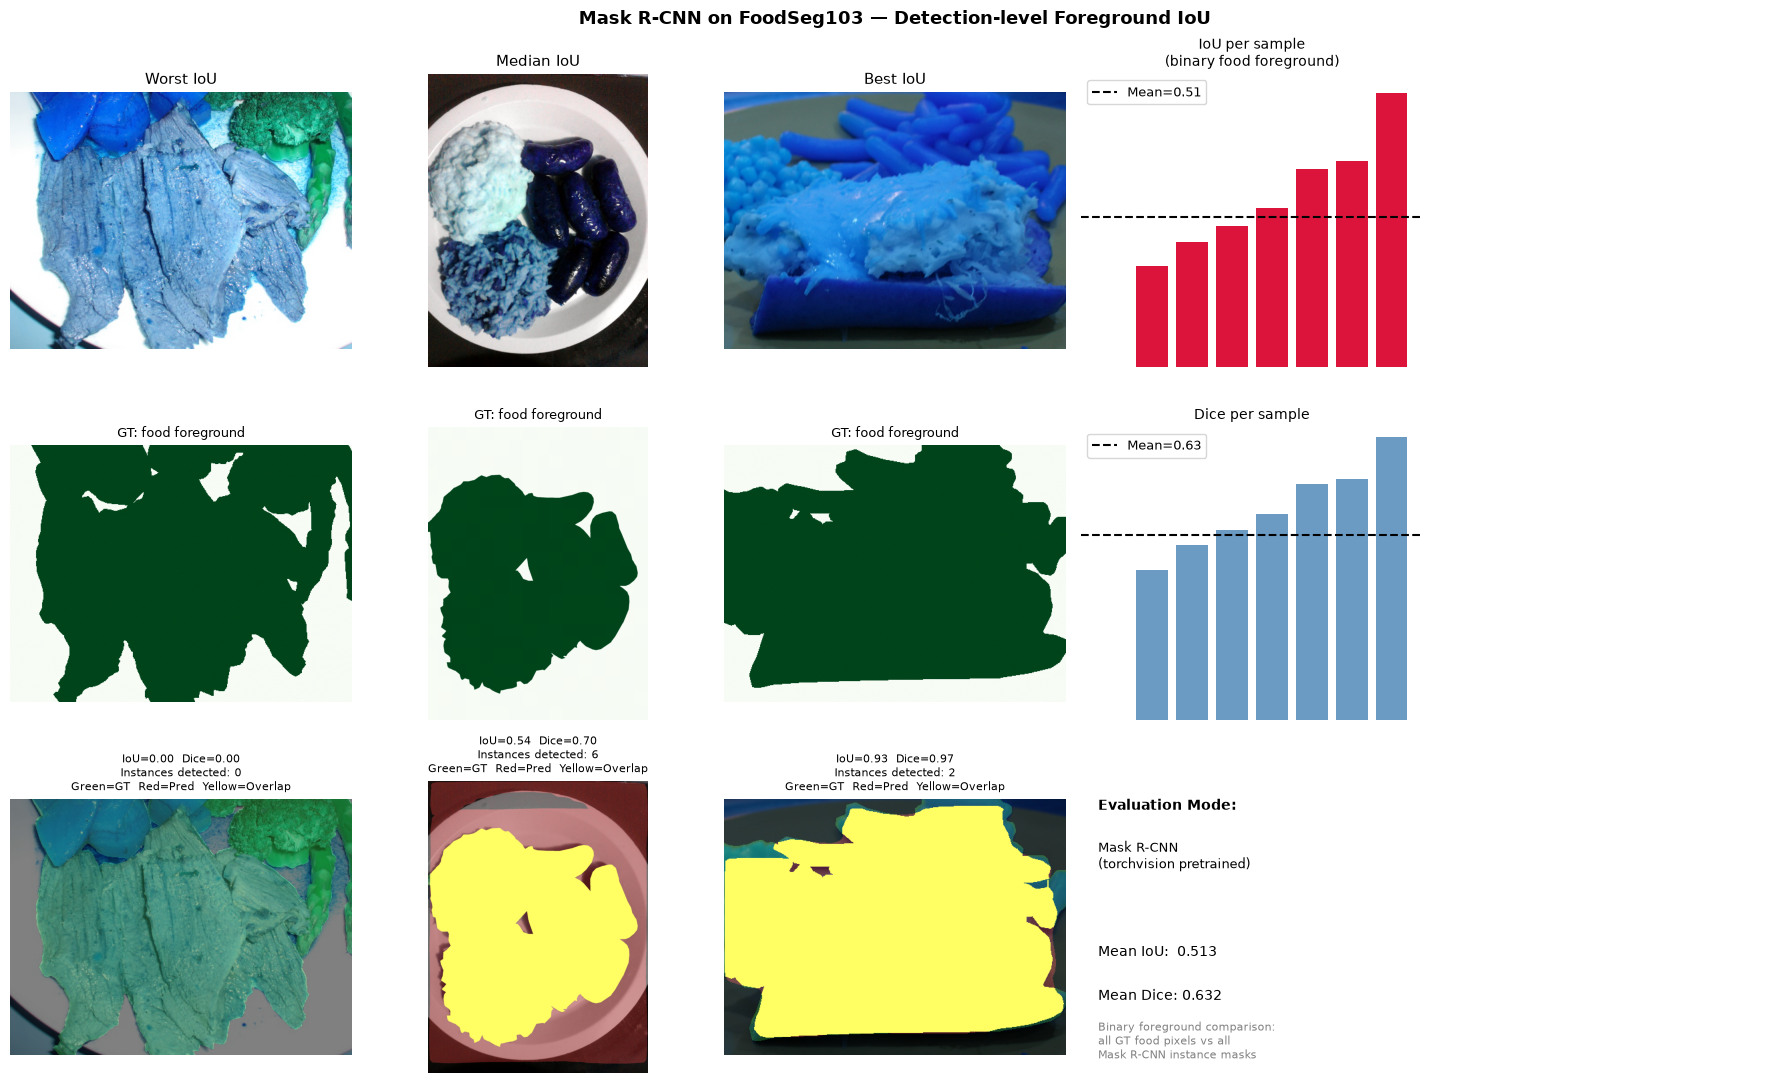

In [8]:
# ── Visualise Mask R-CNN predictions vs GT ────────────────────────────────────
eval_results.sort(key=lambda r: r['iou'])

fig, axes = plt.subplots(3, 5, figsize=(18, 11))
# Row 0: Original image
# Row 1: GT binary mask
# Row 2: Mask R-CNN prediction

examples = [eval_results[0], eval_results[len(eval_results)//2], eval_results[-1]]
titles   = ['Worst IoU', 'Median IoU', 'Best IoU']

for col, (res, title) in enumerate(zip(examples, titles)):
    # Column 0: image
    axes[0, col].imshow(res['image']); axes[0, col].set_title(title, fontsize=11)
    # Column 1: GT mask
    axes[1, col].imshow(res['gt_mask'], cmap='Greens', vmin=0, vmax=255)
    axes[1, col].set_title('GT: food foreground', fontsize=9)
    # Column 2: prediction + GT overlay
    overlay = res['image'].copy()
    pred_rgb = np.zeros_like(overlay)
    gt_rgb   = np.zeros_like(overlay)
    pred_rgb[res['pred_mask'] > 0] = [255, 60, 60]  # red = predicted
    gt_rgb  [res['gt_mask']   > 0] = [60, 200, 60]  # green = GT
    overlap = ((res['pred_mask'] > 0) & (res['gt_mask'] > 0))
    blend = cv2.addWeighted(overlay, 0.5, pred_rgb, 0.3, 0)
    blend = cv2.addWeighted(blend,   1.0, gt_rgb,   0.3, 0)
    blend[overlap] = [255, 255, 100]   # yellow = intersection
    axes[2, col].imshow(blend)
    axes[2, col].set_title(
        f"IoU={res['iou']:.2f}  Dice={res['dice']:.2f}\n"
        f"Instances detected: {res['n_instances']}\n"
        f"Green=GT  Red=Pred  Yellow=Overlap",
        fontsize=8
    )

for ax in axes.ravel():
    ax.axis('off')

# IoU distribution (2 extra columns)
ax_hist = axes[0, 3]
ious = [r['iou'] for r in eval_results]
ax_hist.bar(range(len(ious)), sorted(ious), color=['crimson','orange','steelblue'][0])
ax_hist.axhline(mean_iou, color='k', linestyle='--', label=f'Mean={mean_iou:.2f}')
ax_hist.set_xlabel('Sample (sorted by IoU)'); ax_hist.set_ylabel('IoU')
ax_hist.set_title('IoU per sample\n(binary food foreground)', fontsize=10)
ax_hist.legend(fontsize=9); ax_hist.set_ylim(0, 1)

ax_hist2 = axes[1, 3]
ax_hist2.bar(range(len(ious)), sorted([r['dice'] for r in eval_results]),
             color='steelblue', alpha=0.8)
dice_mean = mean_dice
ax_hist2.axhline(dice_mean, color='k', linestyle='--', label=f'Mean={dice_mean:.2f}')
ax_hist2.set_xlabel('Sample (sorted by Dice)'); ax_hist2.set_ylabel('Dice')
ax_hist2.set_title('Dice per sample', fontsize=10)
ax_hist2.legend(fontsize=9); ax_hist2.set_ylim(0, 1)

ax_note = axes[2, 3]
ax_note.axis('off')
ax_note.text(0.05, 0.9, "Evaluation Mode:", fontsize=10, fontweight='bold', transform=ax_note.transAxes)
mode_str = "Mask R-CNN\n(torchvision pretrained)" if HAS_MRCNN else "Mock threshold\n(torchvision unavailable)"
ax_note.text(0.05, 0.7, mode_str, fontsize=9, transform=ax_note.transAxes)
ax_note.text(0.05, 0.4, f"Mean IoU:  {mean_iou:.3f}", fontsize=10, transform=ax_note.transAxes)
ax_note.text(0.05, 0.25, f"Mean Dice: {mean_dice:.3f}", fontsize=10, transform=ax_note.transAxes)
ax_note.text(0.05, 0.05,
    "Binary foreground comparison:\nall GT food pixels vs all\nMask R-CNN instance masks",
    fontsize=8, color='gray', transform=ax_note.transAxes)

for col in [4]:
    for row in range(3):
        axes[row, col].axis('off')

plt.suptitle("Mask R-CNN on FoodSeg103 — Detection-level Foreground IoU",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


## 6. Evaluating the KNN Embedder on FoodSeg103

FoodSeg103's 103 categories provide a real classification benchmark.

**Setup:**
- For each annotated food region, crop to its bounding box and apply its GT mask (black out everything else)
- Extract HOG features from the masked crop
- Train a KNN classifier on the training split
- Evaluate on the test split
- Report Top-1 and Top-5 accuracy

**Top-5 accuracy:** Correct if the true label appears in the 5 nearest neighbours. This is a standard metric when there are many classes — used in ImageNet evaluation.

In [9]:
# ── Feature extraction on FoodSeg103 crops ───────────────────────────────────

def extract_hog_colour(bgr_crop, image_size=(64, 64)):
    """
    Extract HOG + HSV histogram from a (masked) food crop.
    Inline implementation — no dependency on HOGEmbedder class.
    """
    resized = cv2.resize(bgr_crop, image_size)

    # HOG
    winSize    = image_size
    blockSize  = (16, 16); blockStride = (8, 8); cellSize = (8, 8); nbins = 9
    hog_desc   = cv2.HOGDescriptor(winSize, blockSize, blockStride, cellSize, nbins)
    gray       = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    hog_vec    = hog_desc.compute(gray).flatten()

    # HSV colour histogram
    hsv  = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv],[0,1,2],None,[8,8,8],[0,180,0,256,0,256]).flatten()

    vec  = np.concatenate([hog_vec, hist]).astype(np.float32)
    norm = np.linalg.norm(vec)
    return (vec / norm) if norm > 1e-8 else vec


def build_features_from_dataset(dataset, max_per_category=None):
    """
    For each annotated food region in the dataset, extract features + label.
    Returns X (N, D) and y (N,) arrays.
    """
    X, y = [], []
    cat_counts = defaultdict(int)

    for i in range(len(dataset)):
        sample = dataset[i]
        img, ann = sample['image'], sample['annotation']

        for cat_id in sample['category_ids']:
            if max_per_category and cat_counts[cat_id] >= max_per_category:
                continue

            gt_mask = dataset.get_mask_for_category(ann, cat_id)
            bbox    = dataset.get_bbox_for_mask(gt_mask)
            if bbox is None: continue
            x1, y1, x2, y2 = bbox

            # Skip very small regions (< 20×20 px) — too little information
            if (x2 - x1) < 20 or (y2 - y1) < 20: continue

            # Crop and mask
            crop = img[y1:y2+1, x1:x2+1].copy()
            msk  = gt_mask[y1:y2+1, x1:x2+1]
            crop[msk == 0] = 0     # black out non-food background

            feat = extract_hog_colour(crop)
            X.append(feat)
            y.append(cat_id)
            cat_counts[cat_id] += 1

    return np.array(X, dtype=np.float32), np.array(y)


print("Building training features...")
X_train, y_train = build_features_from_dataset(ds_train, max_per_category=8)
print(f"Train: {X_train.shape[0]} crops, {len(np.unique(y_train))} categories, {X_train.shape[1]} dims")

print("Building test features...")
X_test, y_test = build_features_from_dataset(ds_test, max_per_category=4)
print(f"Test:  {X_test.shape[0]} crops, {len(np.unique(y_test))} categories")


Building training features...
Train: 287 crops, 62 categories, 2276 dims
Building test features...
Test:  156 crops, 56 categories


In [10]:
# ── KNN evaluation with Top-1 and Top-5 accuracy ──────────────────────────────

def knn_topk_accuracy(X_train, y_train, X_test, y_test, k_max=5):
    """
    Evaluate KNN with cosine similarity, returning Top-1 through Top-k accuracy.
    
    Top-k accuracy: prediction is 'correct' if the true label appears
    anywhere in the k nearest neighbours.
    
    This is a single matrix multiplication:
        sim_matrix = X_test @ X_train.T    shape (N_test, N_train)
    Then argsort each row to get nearest neighbours.
    """
    # Cosine similarity matrix (works because vectors are L2-normalised)
    sim_matrix = X_test @ X_train.T     # (N_test, N_train)

    # Sort each row: most similar first (descending)
    sorted_idx  = np.argsort(-sim_matrix, axis=1)   # (N_test, N_train)

    results = {}
    for k in range(1, k_max + 1):
        top_k_labels = y_train[sorted_idx[:, :k]]   # (N_test, k)
        if k == 1:
            correct = (top_k_labels[:, 0] == y_test)
        else:
            correct = np.any(top_k_labels == y_test[:, None], axis=1)
        results[k] = float(correct.mean())

    return results


print("Running KNN evaluation...")
accuracies = knn_topk_accuracy(X_train, y_train, X_test, y_test, k_max=5)

print("\n" + "="*40)
print("KNN Accuracy on FoodSeg103 (HOG + Colour Hist):")
for k, acc in accuracies.items():
    bar = "█" * int(acc * 30)
    print(f"  Top-{k}: {acc*100:5.1f}%  {bar}")
print("="*40)

print("\nComparison reference points:")
print("  Random chance (103 classes): ", f"{1/103*100:.1f}%")
print("  Human-level (approximate):   ~85%  (food recognition is hard even for humans)")
print("  DINOv2 + KNN (pretrained):   ~65–75% on FoodSeg103")


Running KNN evaluation...

KNN Accuracy on FoodSeg103 (HOG + Colour Hist):
  Top-1:   9.0%  ██
  Top-2:  16.0%  ████
  Top-3:  19.9%  █████
  Top-4:  21.2%  ██████
  Top-5:  23.7%  ███████

Comparison reference points:
  Random chance (103 classes):  1.0%
  Human-level (approximate):   ~85%  (food recognition is hard even for humans)
  DINOv2 + KNN (pretrained):   ~65–75% on FoodSeg103


In [11]:
# ── Per-category accuracy breakdown ──────────────────────────────────────────
"""
Which food categories is the HOG+KNN classifier best/worst at?
This is diagnostically useful — categories with low accuracy tell you
where colour/shape features are insufficient (e.g. visually similar foods).
"""

# Build per-category accuracy at K=1
sim_matrix  = X_test @ X_train.T
sorted_idx  = np.argsort(-sim_matrix, axis=1)
pred_top1   = y_train[sorted_idx[:, 0]]

cat_correct = defaultdict(int)
cat_total   = defaultdict(int)

for true, pred in zip(y_test, pred_top1):
    cat_total[true] += 1
    if true == pred:
        cat_correct[true] += 1

# Compute per-category accuracy
cat_acc = {}
for cat_id in cat_total:
    if cat_total[cat_id] >= 2:   # need at least 2 test samples for a reliable estimate
        cat_acc[cat_id] = cat_correct[cat_id] / cat_total[cat_id]

# Sort by accuracy
sorted_cats = sorted(cat_acc.items(), key=lambda x: x[1], reverse=True)

# Show best and worst 10
print("Top 10 easiest categories (HOG gets these right):")
for cat_id, acc in sorted_cats[:10]:
    name = ds_train.get_category_name(cat_id)
    print(f"  {name:25s}  {acc*100:.0f}%  (n={cat_total[cat_id]})")

print("\nTop 10 hardest categories (HOG struggles here):")
for cat_id, acc in sorted_cats[-10:]:
    name = ds_train.get_category_name(cat_id)
    print(f"  {name:25s}  {acc*100:.0f}%  (n={cat_total[cat_id]})")


Top 10 easiest categories (HOG gets these right):
  white radish               100%  (n=4)
  blueberry                  50%  (n=2)
  ice cream                  50%  (n=4)
  okra                       50%  (n=2)
  bread                      25%  (n=4)
  chicken duck               25%  (n=4)
  cheese butter              25%  (n=4)
  strawberry                 25%  (n=4)
  tofu                       25%  (n=4)
  green onion                25%  (n=4)

Top 10 hardest categories (HOG struggles here):
  raspberry                  0%  (n=2)
  pork                       0%  (n=4)
  rice                       0%  (n=4)
  lemon                      0%  (n=4)
  cauliflower                0%  (n=4)
  egg                        0%  (n=2)
  carrot                     0%  (n=2)
  cherry                     0%  (n=3)
  fried meat                 0%  (n=2)
  noodle                     0%  (n=2)


## 7. Depth Estimation on Real Food Images

FoodSeg103 has no ground-truth depth, so we can only **visualise** the classical depth estimator on real food photos. This is still useful — it lets you see where the five cues agree and disagree on real data.

In [12]:
# ── Classical depth estimator (from Notebook 02, inline) ────────────────────

import math
from dataclasses import dataclass

@dataclass
class CameraIntrinsics:
    fx:float; fy:float; cx:float; cy:float; width:int; height:int; source:str="fov"

class ClassicalDepthEstimator:
    def __init__(self, fov_deg=70.0, assumed_d=0.5):
        self.fov_deg = fov_deg; self.assumed_d = assumed_d

    def estimate(self, bgr):
        H, W = bgr.shape[:2]
        fov = math.radians(self.fov_deg)
        fx  = (W/2)/math.tan(fov/2); fy = fx*(H/W)
        K   = CameraIntrinsics(fx=fx,fy=fy,cx=W/2,cy=H/2,width=W,height=H)

        def norm(a):
            lo,hi=a.min(),a.max(); return ((a-lo)/(hi-lo+1e-8)).astype(np.float32)

        gray = cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY).astype(np.float32)
        lap  = cv2.Laplacian(gray,cv2.CV_32F,ksize=3)
        k_   = (15,15)
        blur = norm(np.clip(
            cv2.boxFilter(lap**2,cv2.CV_32F,k_) - cv2.boxFilter(lap,cv2.CV_32F,k_)**2, 0, None))
        pos  = np.tile(np.linspace(0,1,H,dtype=np.float32)[:,None],(1,W))
        hsv  = cv2.cvtColor(bgr,cv2.COLOR_BGR2HSV).astype(np.float32)
        sat  = cv2.GaussianBlur(hsv[:,:,1]/255.,(11,11),0)
        dark_ch = cv2.erode(bgr.min(axis=2).astype(np.float32)/255.,
                             cv2.getStructuringElement(cv2.MORPH_RECT,(15,15)))

        nearness = 0.35*blur + 0.30*pos + 0.20*sat + 0.15*(1.0-dark_ch)
        d_rel    = np.clip(1.0-nearness, 1e-3, 1.0)
        scale    = self.assumed_d/max(float(np.median(d_rel)),1e-3)
        return (d_rel*scale).astype(np.float32), K

de = ClassicalDepthEstimator()
print("Depth estimator ready.")


Depth estimator ready.


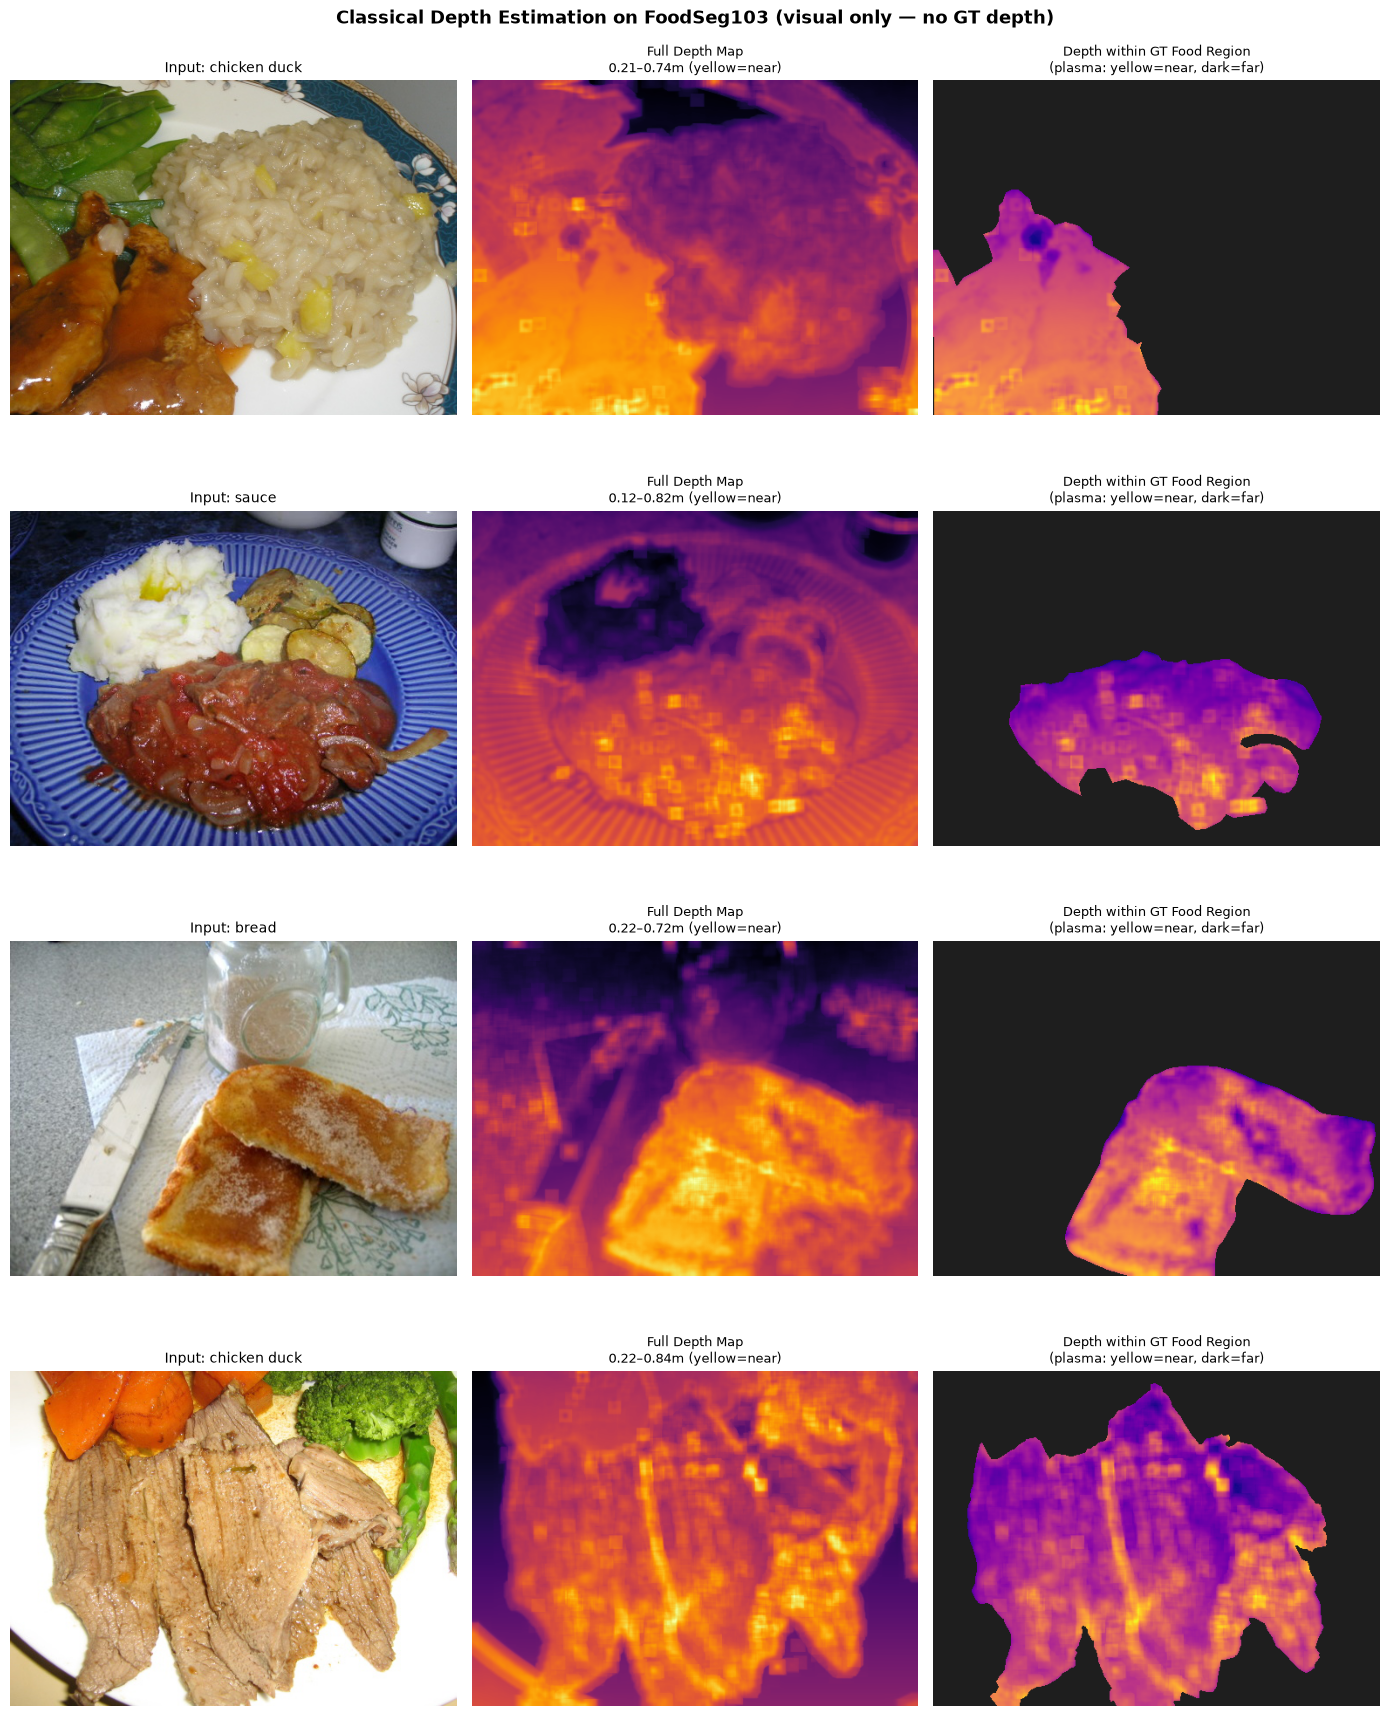

In [13]:
# ── Run depth on 4 real food samples ─────────────────────────────────────────
n_depth = min(4, len(ds_train))
fig, axes = plt.subplots(n_depth, 3, figsize=(14, 4.5*n_depth))
if n_depth == 1: axes = axes[np.newaxis,:]

for row, i in enumerate(range(n_depth)):
    sample  = ds_train[i]
    img     = sample['image']
    ann     = sample['annotation']
    cat_id  = sample['category_ids'][0] if sample['category_ids'] else 0
    gt_mask = ds_train.get_mask_for_category(ann, cat_id) if cat_id else np.zeros(img.shape[:2],np.uint8)

    depth_map, _ = de.estimate(img)

    # Depth visualisation
    lo, hi = depth_map.min(), depth_map.max()
    norm_d  = ((depth_map-lo)/(hi-lo+1e-8)*255).astype(np.uint8)
    depth_vis = cv2.applyColorMap(255-norm_d, cv2.COLORMAP_INFERNO)

    # Overlay depth on food region only
    food_depth = depth_map.copy()
    food_depth[gt_mask==0] = 0
    food_lo = depth_map[gt_mask>0].min() if gt_mask.sum()>0 else lo
    food_hi = depth_map[gt_mask>0].max() if gt_mask.sum()>0 else hi
    food_norm = np.zeros_like(norm_d)
    if food_hi > food_lo:
        food_norm[gt_mask>0] = ((depth_map[gt_mask>0]-food_lo)/(food_hi-food_lo)*255).astype(np.uint8)
    food_vis = cv2.applyColorMap(255-food_norm, cv2.COLORMAP_PLASMA)
    food_vis[gt_mask==0] = [30,30,30]

    axes[row,0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[row,0].set_title(f"Input: {ds_train.get_category_name(cat_id)}", fontsize=10); axes[row,0].axis("off")

    axes[row,1].imshow(cv2.cvtColor(depth_vis, cv2.COLOR_BGR2RGB))
    axes[row,1].set_title(f"Full Depth Map\n{lo:.2f}–{hi:.2f}m (yellow=near)", fontsize=9); axes[row,1].axis("off")

    axes[row,2].imshow(cv2.cvtColor(food_vis, cv2.COLOR_BGR2RGB))
    axes[row,2].set_title("Depth within GT Food Region\n(plasma: yellow=near, dark=far)", fontsize=9); axes[row,2].axis("off")

plt.suptitle("Classical Depth Estimation on FoodSeg103 (visual only — no GT depth)",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


## 8. Summary — What FoodSeg103 Tells Us About Our Scratch Models

### Segmenter (Mask R-CNN, binary detection IoU)

| IoU range | Interpretation |
|---|---|
| > 0.70 | Strong foreground detection — food region well covered |
| 0.40–0.70 | Partial detection — food detected but with gaps or false positives |
| < 0.40 | Weak detection — Mask R-CNN confused by plate, background, or no COCO match |

**Key limitation:** Mask R-CNN is pretrained on COCO (80 general categories).  
Most FoodSeg103 dishes are not in COCO.  
We evaluate binary foreground coverage — a weaker criterion than per-category IoU.  
For true category-level evaluation, train Mask R-CNN or SegFormer on FoodSeg103 directly.

**Instance vs Semantic:** Mask R-CNN gives one mask per object — great for PortionVision (we want per-dish masks).  
FoodSeg103 evaluates semantic labels — same category = same label.  
These two paradigms measure different things.

### Embedder (HOG + KNN on 103 classes)

| Top-K | Expected accuracy | Baseline (random) |
|---|---|---|
| Top-1 | ~5–20% | 1% |
| Top-5 | ~20–50% | 5% |

HOG+KNN struggles on 103-class food — food categories have high visual similarity.  
DINOv2 embeddings improve this substantially — see Notebook 03.

### Depth (classical cues — qualitative)

No ground-truth depth in FoodSeg103 → visual inspection only.  
Classical depth maps show plausible far/near structure for most images.  
True evaluation would require an RGBD dataset (e.g., NYUv2-food).

### Production system comparison

| Component | Scratch (this notebook) | Production (PVsys) |
|---|---|---|
| Segmentation | Mask R-CNN (COCO 80 classes) | SAM 2 (class-agnostic, 600M params) |
| Embedding | HOG + cosine KNN | DINOv2 ViT-B/14, 768-dim |
| Depth | 5-cue classical fusion | Depth Pro (metric, RGBD-trained) |
| Volume | RANSAC + discrete integration | Same (shared) |

The scratch models are intentionally simpler — their purpose is to make the production models' design choices comprehensible by contrast.